# Reading the thermal spectrum of a real molecular-cloud field

## 1. Problem: temperature and material overlap

Thermal dust images carry both spectral shape and amplitude information. We reconstruct two spatial fields from three real COBE DIRBE far-infrared maps: apparent single-temperature colour temperature and apparent dust surface density. They are conditional on fixed emissivity and a monochromatic approximation, not actual grain-by-grain temperature or measured cloud mass. The original PTS greybody fitter supplies an independently run method reference; no physical truth is available.

In [1]:
from pathlib import Path
import sys,time,json,os,platform
import numpy as np,scipy
import matplotlib,matplotlib.pyplot as plt
root=Path.cwd()
if root.name=='notebooks':root=root.parent
sys.path.insert(0,str(root))
from src.preprocessing import load_data
from src.solvers import reconstruct
from src import visualization as viz
print('ACTUAL_KERNEL_ENVIRONMENT',json.dumps({'executable':sys.executable,'python':sys.version,'os':platform.platform(),'numpy':np.__version__,'numpy_file':np.__file__,'scipy':scipy.__version__,'matplotlib':matplotlib.__version__,'backend':matplotlib.get_backend(),'threads':{k:os.environ.get(k) for k in ['OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS']}}))
data=load_data(root/'data/raw_data.npz')
with np.load(root/'notebooks/reference_outputs/upstream_measurements.npz',allow_pickle=False) as f:author=np.stack([f[k][0] for k in ['reconstruction','surface_density']])
sources={}
def show(name,result):
    fig,numeric=result;sources.update({name+'_'+k:v for k,v in numeric.items()});plt.show()
print({k:v.shape for k,v in data.items()})

ACTUAL_KERNEL_ENVIRONMENT {"executable": "D:\\yan1\\agent\\AutoSkill\\imaging-101-maintainer\\research-runtime\\Scripts\\python.exe", "python": "3.11.11 (main, Mar 17 2025, 21:01:29) [MSC v.1943 64 bit (AMD64)]", "os": "Windows-10-10.0.26200-SP0", "numpy": "2.4.6", "numpy_file": "D:\\yan1\\agent\\AutoSkill\\imaging-101-maintainer\\research-runtime\\Lib\\site-packages\\numpy\\__init__.py", "scipy": "1.17.1", "matplotlib": "3.11.1", "backend": "module://matplotlib_inline.backend_inline", "threads": {"OMP_NUM_THREADS": "1", "OPENBLAS_NUM_THREADS": "1", "MKL_NUM_THREADS": "1"}}
{'intensity': (3, 32, 48), 'uncertainty': (3, 32, 48), 'galactic_longitude': (32, 48), 'galactic_latitude': (32, 48), 'wavelengths': (3,), 'response_wavelength': (249,), 'spectral_response': (3, 249)}


## 2. Data: the actual sky and its uncertainty

These are the100,140,240μm ZSMA mission-average products over a32×48 Taurus sampling field. Each observation is an unchanged native sky pixel promoted from float32 to float64; the actual native centre coordinates are supplied. The nominal beam is0.7°×0.7°, so neighboring samples are correlated. The uncertainty is the source product's scatter of weekly means, used as relative channel weights rather than a complete independent-noise model. Zodiacal subtraction is already part of the source product. No reference-derived spatial template or hidden temperature calibration enters the observations.

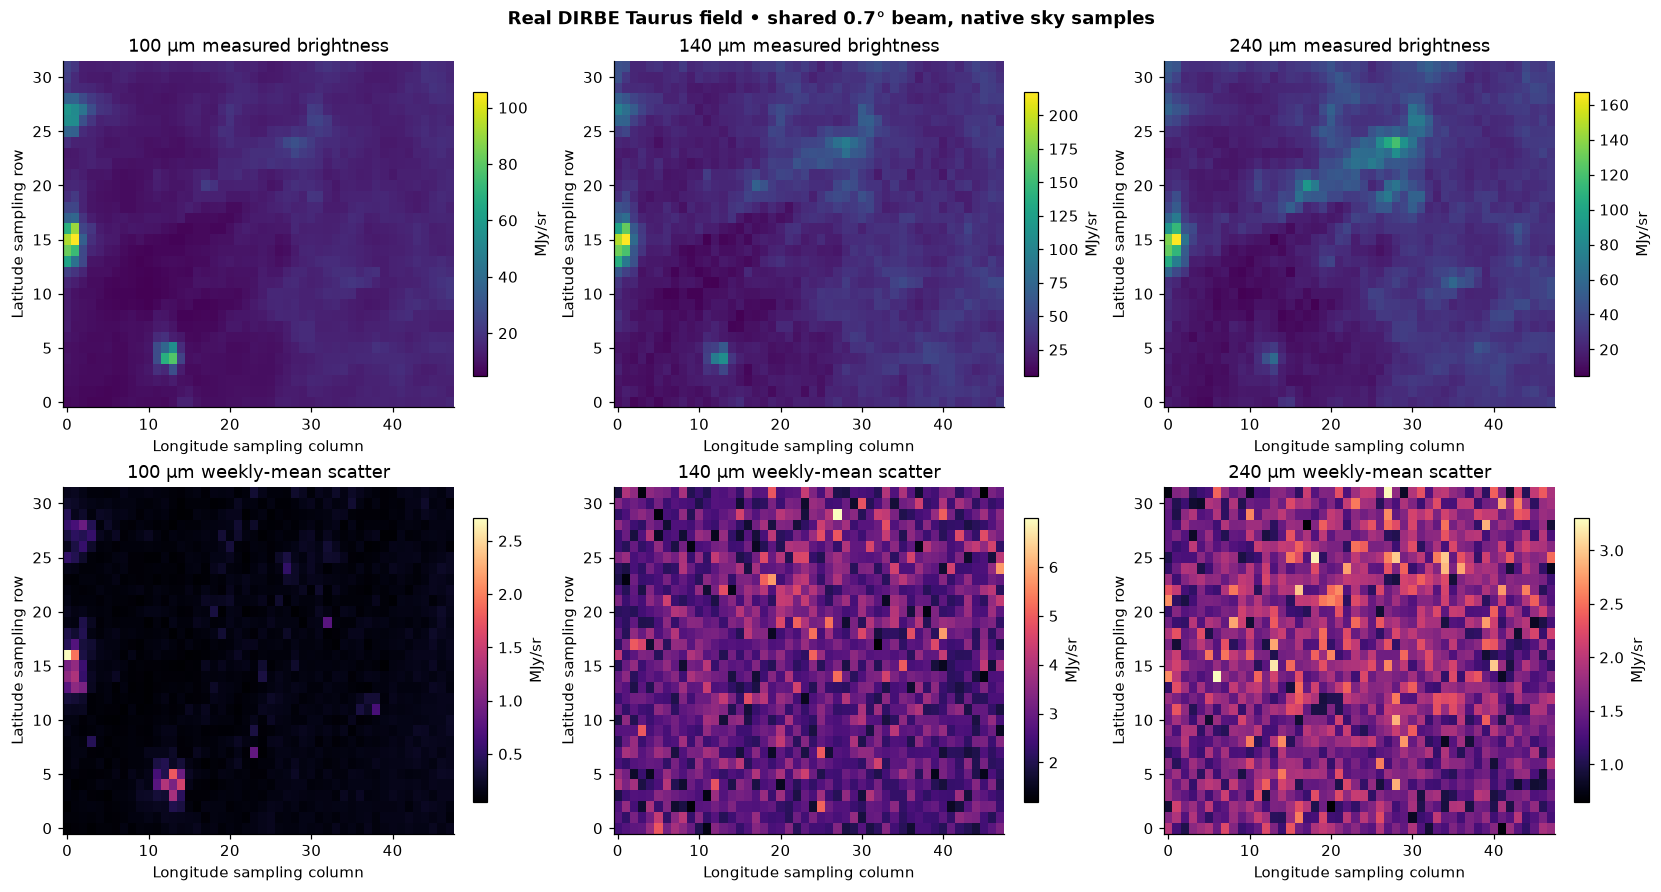

In [2]:
show('acquisition',viz.acquisition(data))

## 3. Physics and the selected inverse

The optically thin monochromatic model is

$$I_\nu=\Sigma\kappa_{350}(\nu/\nu_{350})^2B_\nu(T),\qquad B_\nu(T)=\frac{2h\nu^3}{c^2[\exp(h\nu/(kT))-1]}.$$

Here specific intensity is SI radiance, Sigma is kg/m², temperature T is K, and opacity at350μm is0.192m²/kg. One MJy/sr equals1e-20SI radiance. The temperature controls spectral curvature, while the column multiplies amplitude. We minimize the sum of squared channel residuals divided by the supplied relative uncertainties. The original unconstrained Levenberg–Marquardt fit starts at20K and preserves the original coefficient scaling. Its historical physical constants and numerical conventions are retained. Every pixel is fitted independently, without smoothing or hidden data.

The numerical coefficient M used inside the fitter obeys Sigma=M Msun/pc². It represents an arbitrary one-steradian reference area at1pc solely for numerical unit conversion; no physical distance to the Taurus cloud is assumed. Local source explicitly implements Planck radiation, opacity, radiance, the Jacobian and fitting objective. Frozen independent original outputs test the same exact observations.

D:\yan1\agent\AutoSkill\imaging-101-release\tasks\dirbe_dust_colour_temperature_density\src\physics_model.py:16: RuntimeWarning: overflow encountered in exp
  return 2*H*nu**3/C**2/(np.exp(H*nu/(K*temperature))-1)


Fresh complete reconstruction seconds: 0.996954200003529


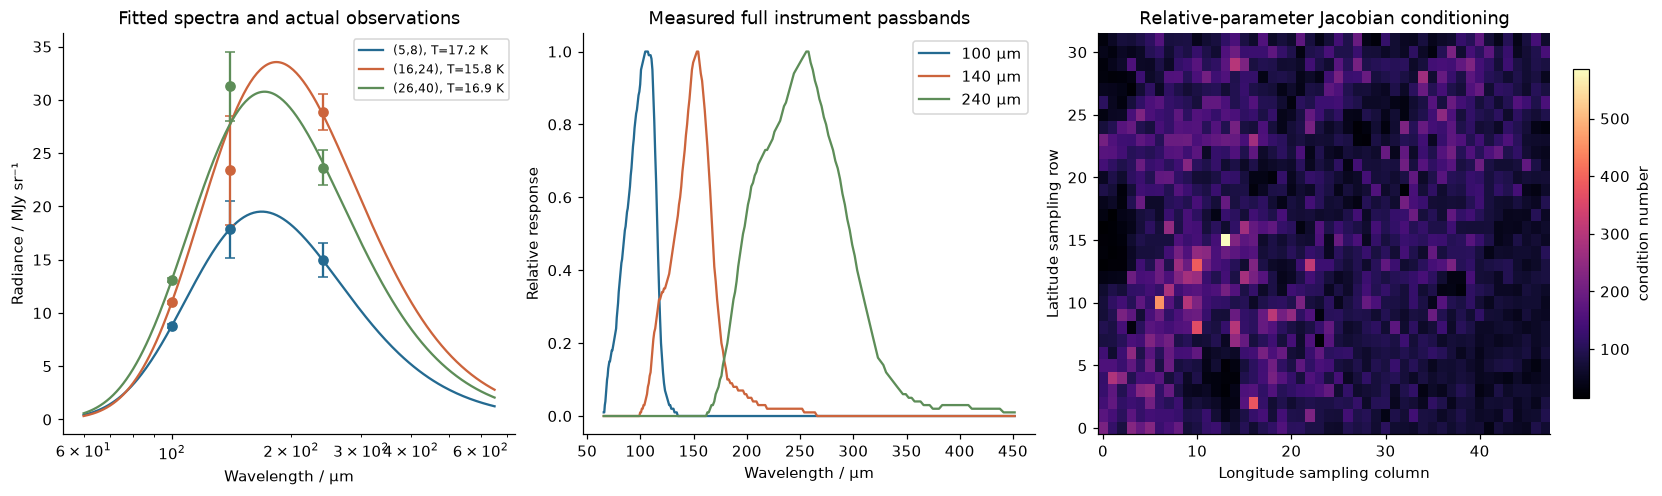

In [3]:
start=time.perf_counter()
maps,prediction=reconstruct(data)
runtime=time.perf_counter()-start
print('Fresh complete reconstruction seconds:',runtime)
show('physics',viz.physics(data,maps))

## 4. Reproduction and evaluation

Original PTS fields below were computed on these exact bound observations before writing the local method. Fresh fields are reconstructed above during this execution. Their agreement validates extraction of this selected fitting model; it does not establish astrophysical truth. Temperature and surface density are scored separately, using cosine NCC without centering and RMS error divided by each reference field's dynamic range. The strict standalone evaluator applies no image transformations.

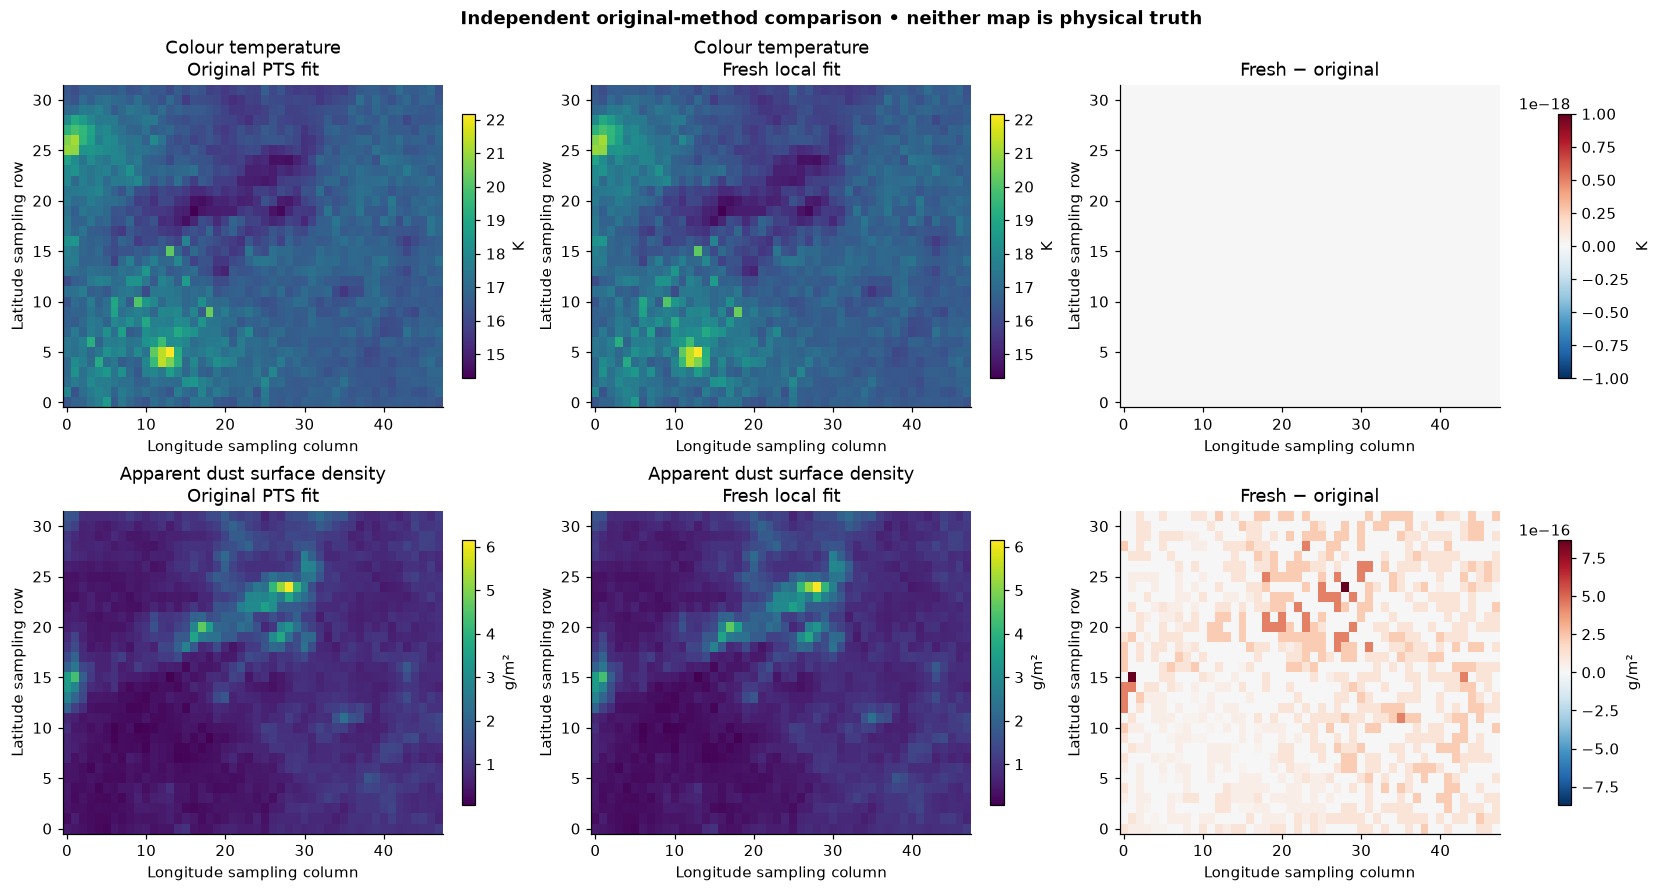

temperature_K {'cosine_NCC': 0.9999999999999998, 'dynamic_range_NRMSE': 0.0}
surface_density_kg_m2 {'cosine_NCC': 0.9999999999999999, 'dynamic_range_NRMSE': 1.9087426452506302e-17}
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "reconstruction_ncc": 0.9999999999999998,
    "reconstruction_nrmse": 0.0,
    "surface_density_ncc": 0.9999999999999999,
    "surface_density_nrmse": 1.9087426452506302e-17
  },
  "thresholds": {
    "reconstruction_ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "reconstruction_nrmse": {
      "comparison": "<=",
      "boundary": 1e-05
    },
    "surface_density_ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "surface_density_nrmse": {
      "comparison": "<=",
      "boundary": 1e-05
    }
  },
  "errors": []
}


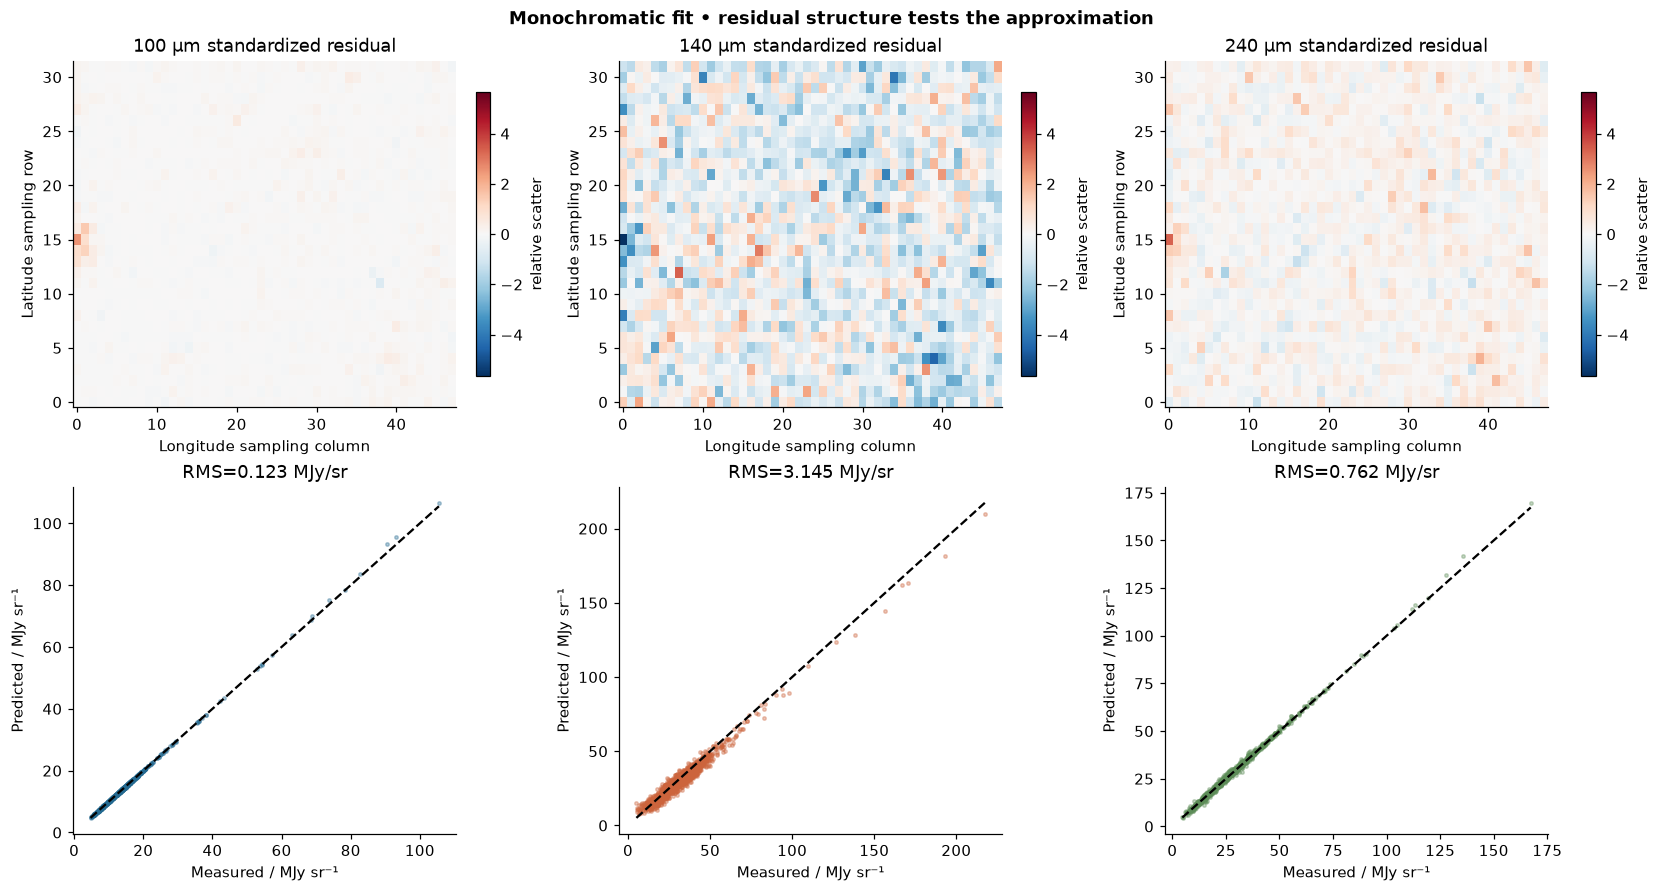

In [4]:
show('components',viz.components(maps,author))
from importlib.util import spec_from_file_location,module_from_spec
sp=spec_from_file_location('independent_judge',root/'evaluation/judge.py');judge=module_from_spec(sp);sp.loader.exec_module(judge)
for i,name in enumerate(['temperature_K','surface_density_kg_m2']):
    print(name,dict(zip(['cosine_NCC','dynamic_range_NRMSE'],judge.compare(maps[i],author[i]))))
np.savez_compressed(root/'output/reconstruction.npz',reconstruction=maps[0][None],surface_density=maps[1][None])
report,code=judge.evaluate(root/'output/reconstruction.npz');assert code==0
print(json.dumps(report,indent=2))
show('residuals',viz.residuals(data,prediction))

## 5. Experiments: known bandpass bias and spectral assumptions

DIRBE quotes broad-band brightness for a calibration spectrum with constant nu*I. Treating those numbers as monochromatic is an approximation. We use the actual response R to diagnose its bias, computing

$$J_b=\frac{\int I_\nu R_b(\nu)\,d\nu}{\int(\nu_b/\nu)R_b(\nu)\,d\nu},\qquad K_b=J_b/I_{\nu_b}.$$

The monochromatic brightness corresponding to a quoted measurement is quoted/K. Here the full-response calculation is a separately labeled prediction from the same fitted fields, not a replacement for the specified original monochromatic method. Comparing residual distributions reveals this known modeling limitation. We then actually refit the complete field at seven fixed emissivity exponents. Changes in temperature and column illustrate conditional identifiability; choosing a smaller residual is not proof of a more accurate physical field.

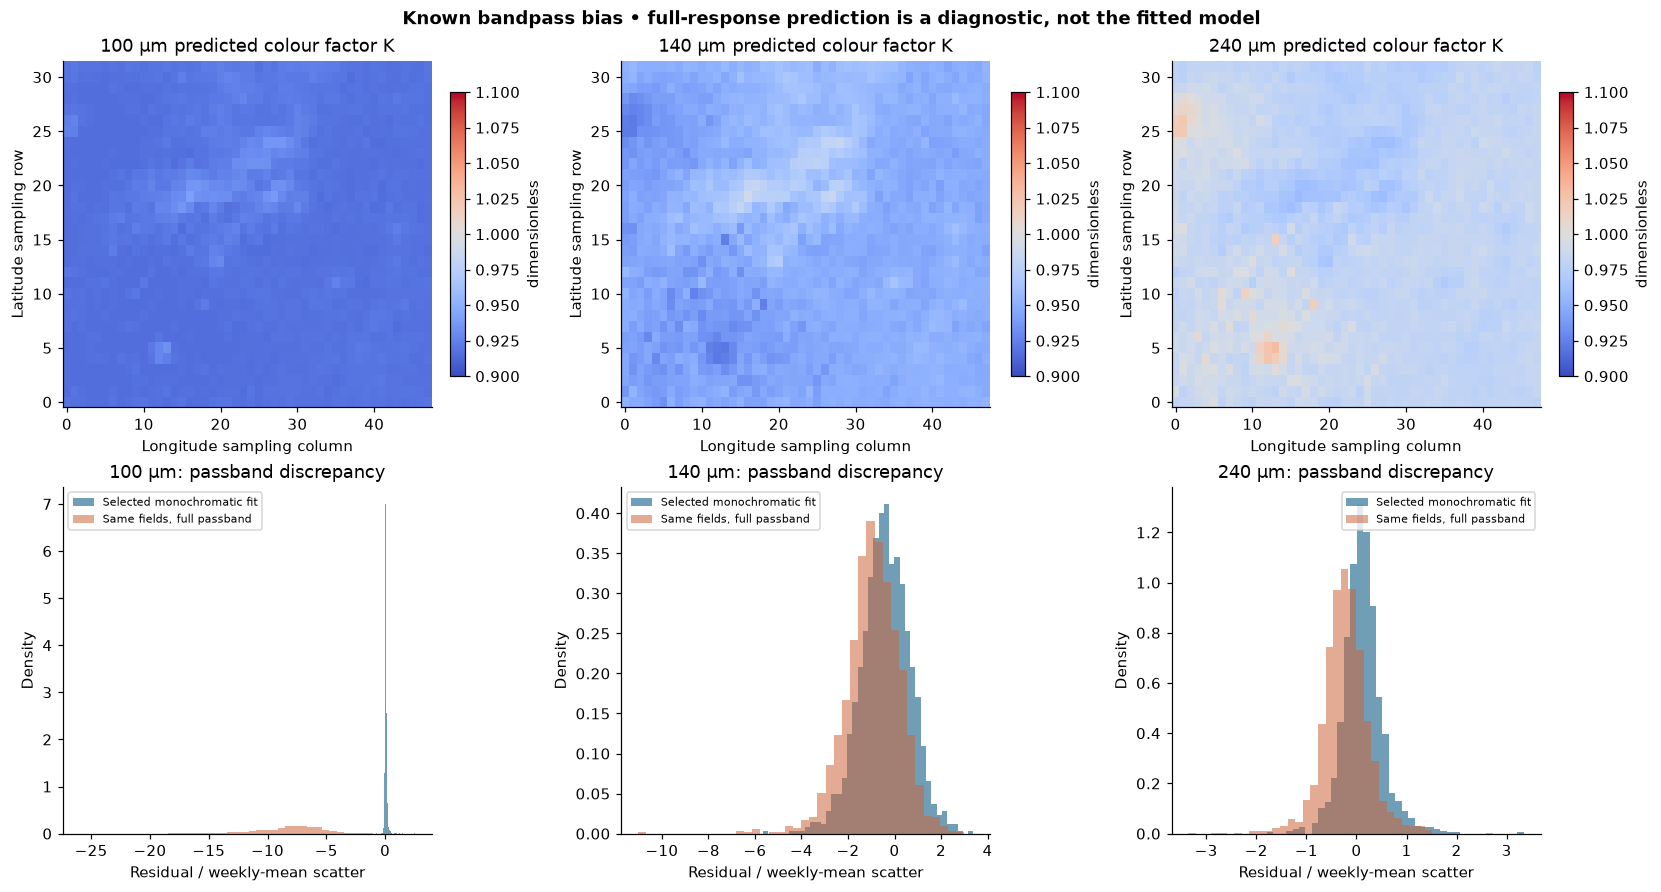

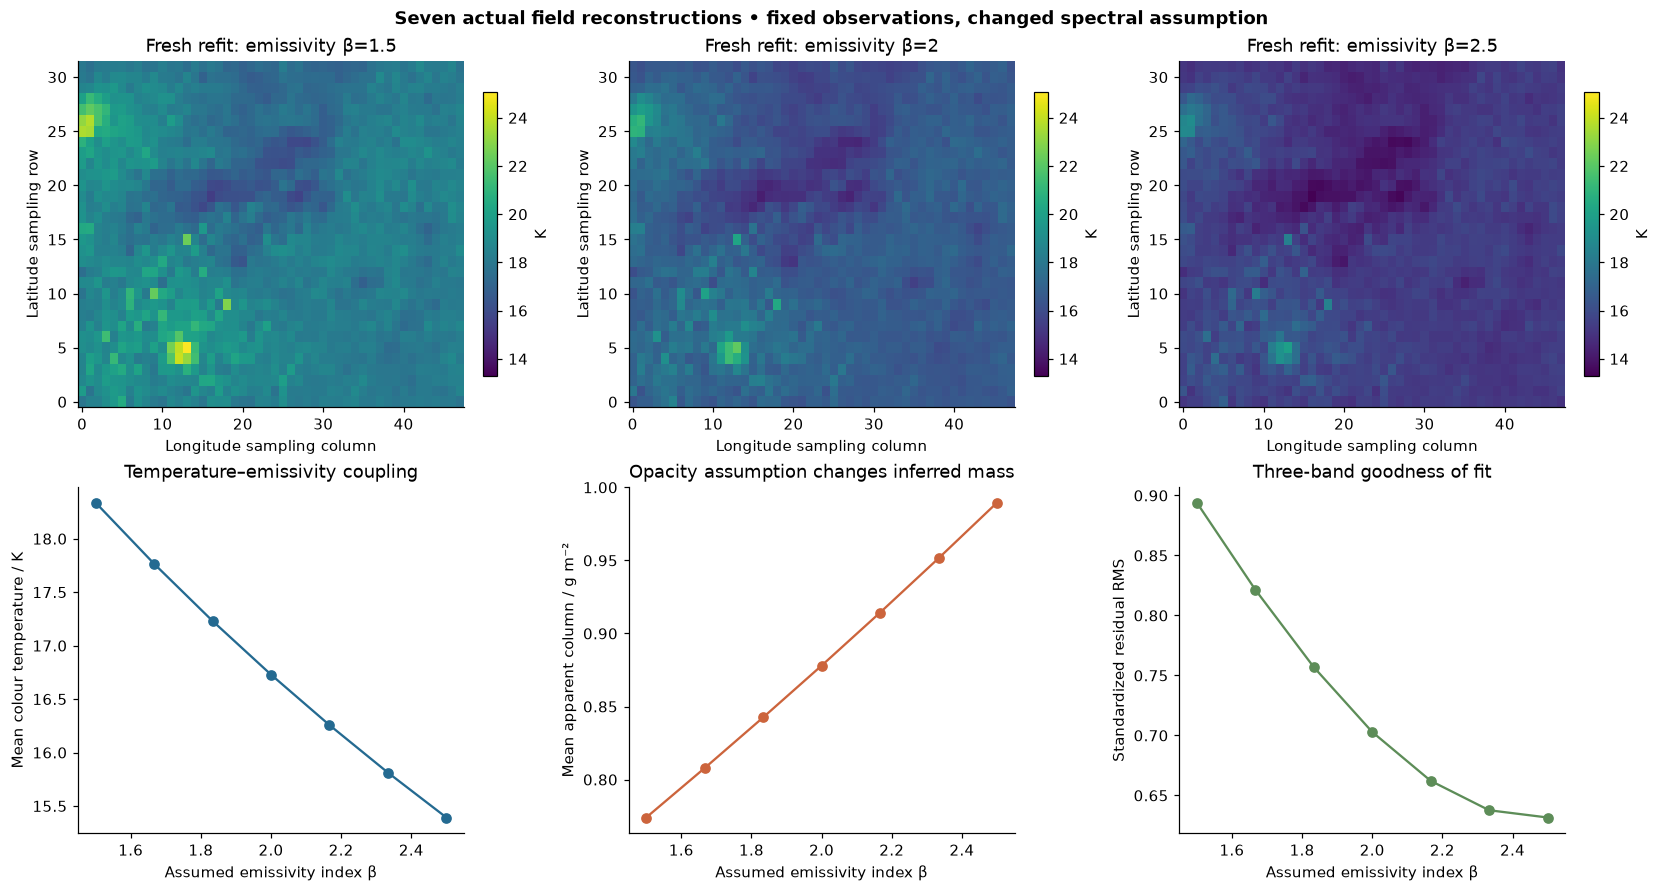

In [5]:
show('colour_diagnostic',viz.colour_diagnostic(data,maps,prediction))
show('sensitivity',viz.sensitivity(data,maps))

## 6. Conclusion and interpretation

The fresh local implementation reproduces the independently executed original monochromatic greybody fit while preserving real cloud morphology. The explicit full-response diagnostics show why these are apparent colour parameters. Three broad bands cannot independently identify temperature mixtures, emissivity variations, opacity normalization and column; correlated sky pixels also do not add independent spectral information. The source paper's galaxy simulations are historical context rather than measurements reproduced here. All displayed alternatives are computed from these same real observations during this execution; none is substituted from a cache.

In [6]:
print('Active reconstruction and all sensitivity refits completed; plot-source arrays:',len(sources))

Active reconstruction and all sensitivity refits completed; plot-source arrays: 16
